![Banner](../../../../Images/Banner/07_remote_sensing/09_08_banner_rs_super_resolution.png)


# Landsat 8 to Sentinel-2: six-band super-resolution

This tutorial uses the supplied AOI-clipped **Landsat 8 Collection 2 Level-2 surface-reflectance scene from 2019-07-09** and **Sentinel-2A Level-2A surface-reflectance scene from 2019-07-08**.


## Overview

The acquisitions are one day apart and both are atmospherically corrected reflectance products, making this a much better paired example than cross-season or L1C/Level-2 comparisons.

We use six common bands: **blue, green, red, NIR, SWIR1, and SWIR2**. The provided Sentinel-2 stack already aligns to the Landsat AOI footprint at a 10 m output grid. Sentinel-2 SWIR1/SWIR2 are natively 20 m and have been bilinearly interpolated to that grid; the resampling does not make them true 10 m observations.

The notebook uses GeoLattice raster I/O and super-resolution functions. It compares interpolation, sharpening, a simple degradation-model reconstruction, and an EDSR-style CNN trained on spatially separated Landsat/Sentinel patch pairs. All validation metrics are against Sentinel-2-not a known fine-resolution Landsat truth. Sensor bandpass differences, residual co-registration, and SWIR resolution remain sources of disagreement. Treat the results as an experiment, not a sensor-calibrated 10 m Landsat product.


## Workflow and package functions

1. Read the clipped reflectance stacks and clear masks with `geolattice.rsense.read`.
2. Compare their CRS, footprint, pixel size, and matching band order; make valid-pixel masks.
3. Run `geolattice.rsense.super_resolution.upsample`, `unsharp_mask`, and `iterative_back_projection` as classical methods.
4. Train and apply `build_sr_model`, `train_super_resolution`, and `predict_super_resolution` on spatially separated patches.
5. Compare held-out RMSE/PSNR/SAM, visualize products, and write GeoTIFFs using `geolattice.rsense.write`.

Install GeoLattice and the optional neural dependencies with `pip install "geolattice[rsense-dl]"`. The neural-network section needs PyTorch; all raster reading, classical methods, and GeoTIFF writing use GeoLattice APIs.


### Imports and data locations

This cell imports GeoLattice for georeferenced raster I/O and SR operations, PyTorch for training, and NumPy/SciPy for array preparation and metrics. It locates the GeoLattice checkout so the same notebook can use the current source tree when run there; otherwise Python uses the installed package. The paths point to the supplied July 2019 datasets, and outputs default to a dedicated folder beside the inputs.


**Installation.** This notebook needs installation option 6 (every GeoLattice module): `pip install "geolattice[all]"`. See "Installation options" in the GeoLattice README.

In [1]:
from pathlib import Path  # file paths
import json  # read the scene metadata JSON
import os  # environment variables and CPU count
import sys  # Python import path

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import torch  # PyTorch: the neural super-resolution model
import xarray as xr  # labelled arrays and result tables
from scipy.ndimage import distance_transform_edt  # distance to the nearest valid pixel (gap filling)
from torch.utils.data import DataLoader, TensorDataset  # feed patches to PyTorch in batches

# Prefer this checkout's code when launched from the repository.
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "pyproject.toml").exists() and (p / "src" / "rsense").is_dir()), None)
if ROOT is not None:  # a checkout was found
    sys.path.insert(0, str(ROOT / "src"))  # import GeoLattice from its src folder

from geolattice import rsense as rs  # GeoLattice remote sensing
from geolattice.rsense import super_resolution as sr  # super-resolution tools

if ROOT is None:  # not started inside the repository
    # stop with a clear message
    raise FileNotFoundError("Start Jupyter from the GeoLattice checkout or one of its subdirectories")
# this notebook's folder
NOTEBOOK_DIR = ROOT / "Tutorials" / "notebooks" / "08_remote_sensing" / "09_08_image_super_resolution"
DATA_DIR = NOTEBOOK_DIR / "../../../../Data/08_remote_sensing/08_08_image_super_resolution"  # its data folder
LANDSAT_DIR = DATA_DIR / "Landsat8_20190709"  # Landsat 8 scene folder
SENTINEL_DIR = DATA_DIR / "Sentinel_2" / "L2A_T17TQH_20190708"  # Sentinel-2 scene folder
# Landsat 8 surface reflectance, 30 m
LANDSAT_PATH = LANDSAT_DIR / "landsat8_20190709_surface_reflectance_30m.tif"
LANDSAT_MASK_PATH = LANDSAT_DIR / "clear_mask.tif"  # Landsat clear-sky mask
# Sentinel-2 surface reflectance, 6 bands, 10 m
SENTINEL_PATH = SENTINEL_DIR / "sentinel2_20190708_surface_reflectance_6band_10m.tif"
SENTINEL_MASK_PATH = SENTINEL_DIR / "clear_mask_10m.tif"  # Sentinel-2 clear-sky mask
# Every input is a prepared clip of the study area kept in data/; there is no public download
# for these clips, so stop with a clear message when one is missing from the local drive.
INPUTS = [LANDSAT_PATH, LANDSAT_MASK_PATH, SENTINEL_PATH, SENTINEL_MASK_PATH]  # the input rasters of this notebook
missing = [str(p) for p in INPUTS if not p.exists()]  # inputs not found on the local drive
if missing:  # stop early with the list of missing files
    raise FileNotFoundError("Copy these files into the data folder first: " + ", ".join(missing))
print("Reading", len(INPUTS), "input rasters from", DATA_DIR)  # all inputs are local

# output folder (can be changed with an environment variable)
OUTPUT_DIR = Path(os.environ.get("GEOLATTICE_SR_OUTPUT", DATA_DIR / "super_resolution_outputs"))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)  # create it if needed

BANDS = ["blue", "green", "red", "nir", "swir1", "swir2"]  # the six bands both sensors share
SCALE = 3  # 30 m Landsat pixels to the 10 m comparison grid
PATCH = 12  # low-resolution Landsat patch width in pixels
SEED = 7  # random seed
torch.manual_seed(SEED)  # same initial weights on every run
torch.set_num_threads(min(4, os.cpu_count() or 1))  # use at most four CPU threads
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"  # use the GPU when available
print("GeoLattice checkout:", ROOT)  # repository path
print("PyTorch:", torch.__version__, "| device:", DEVICE)  # PyTorch version and device
print("Output folder:", OUTPUT_DIR)  # output folder

GeoLattice checkout: /media/zia207/SSD/GitHub/GeoLattice
PyTorch: 2.10.0+cu128 | device: cuda
Output folder: /media/zia207/SSD/GitHub/GeoLattice/Tutorials/notebooks/09_remote_sensing/09_08_image_super_resolution/data/super_resolution_outputs


### Read reflectance and scene metadata with GeoLattice

`rs.read` returns georeferenced xarray `DataArray` objects with CRS, transform, coordinates, and masked nodata represented as NaN. Landsat stores seven bands; `.sel(band=BANDS)` selects the six requested bands by their descriptions. Sentinel-2 is already a six-band surface-reflectance stack. The JSON sidecars record acquisition dates, source scenes, reflectance scaling, native band resolutions, and the cloud-mask rules.


In [2]:
landsat_metadata = json.loads((LANDSAT_DIR / "metadata.json").read_text())  # Landsat scene metadata
sentinel_metadata = json.loads((SENTINEL_DIR / "metadata.json").read_text())  # Sentinel-2 scene metadata

landsat_all = rs.read(  # read the Landsat stack
    LANDSAT_PATH,
    band_names=["coastal", "blue", "green", "red", "nir", "swir1", "swir2"],
)
landsat = landsat_all.sel(band=BANDS)  # keep the six shared bands
sentinel = rs.read(SENTINEL_PATH, band_names=BANDS)  # read the Sentinel-2 stack with band names

# Read one-band clear masks; 1 means clear and 0 means masked.
landsat_clear = rs.read(LANDSAT_MASK_PATH, band_names=["clear"]).isel(band=0, drop=True)
# Sentinel-2 clear mask as a 2-D array
sentinel_clear = rs.read(SENTINEL_MASK_PATH, band_names=["clear"]).isel(band=0, drop=True)

print("Landsat:", landsat_metadata["scene_id"], landsat_metadata["acquired"])  # Landsat scene ID and date
# Sentinel-2 scene ID and date
print("Sentinel-2:", sentinel_metadata["scene_id"], sentinel_metadata["acquired"])
print("Landsat shape/bands:", landsat.shape, list(landsat.band.values))  # Landsat shape and bands
print("Sentinel shape/bands:", sentinel.shape, list(sentinel.band.values))  # Sentinel-2 shape and bands
# cloud share in the AOI
print("Sentinel AOI cloud (%):", sentinel_metadata["aoi_cloud_percent_scl_classes_8_9_10"])

Landsat: LC08_L2SP_017030_20190709_02_T1 2019-07-09T15:57:32.899443+00:00
Sentinel-2: S2A_MSIL2A_20190708T155911_R097_T17TQH_20201005T110153 2019-07-08T15:59:11.024000+00:00
Landsat shape/bands: (6, 203, 189) [np.str_('blue'), np.str_('green'), np.str_('red'), np.str_('nir'), np.str_('swir1'), np.str_('swir2')]
Sentinel shape/bands: (6, 609, 567) [np.str_('blue'), np.str_('green'), np.str_('red'), np.str_('nir'), np.str_('swir1'), np.str_('swir2')]
Sentinel AOI cloud (%): 0.021332


### Verify grid alignment and build valid masks

The prepared products should share CRS, AOI bounds, 10 m output transform, shape, and band order. Landsat's 30 m image covers exactly the same footprint at one-third the pixel dimensions. We assert those facts rather than silently resampling one scene to another. Clear masks and finite reflectance values define valid pixels; the paired mask further restricts training and evaluation to locations valid in both dates.


In [3]:
assert landsat.rio.crs == sentinel.rio.crs  # same CRS
assert landsat.rio.bounds() == sentinel.rio.bounds()  # same footprint
assert landsat.shape[0] == sentinel.shape[0] == len(BANDS)  # same number of bands
assert landsat.shape[1] * SCALE == sentinel.shape[1]  # Sentinel-2 rows = 3 x Landsat rows
assert landsat.shape[2] * SCALE == sentinel.shape[2]  # Sentinel-2 columns = 3 x Landsat columns
assert list(landsat.band.values) == list(sentinel.band.values) == BANDS  # same band order
assert np.allclose(landsat.rio.resolution(), (30, -30))  # Landsat pixels are 30 m
assert np.allclose(sentinel.rio.resolution(), (10, -10))  # Sentinel-2 pixels are 10 m

landsat_values = np.asarray(landsat.values, dtype="float32")  # Landsat as a float array
sentinel_values = np.asarray(sentinel.values, dtype="float32")  # Sentinel-2 as a float array
# clear and finite in every band
landsat_valid = (landsat_clear.values == 1) & np.isfinite(landsat_values).all(axis=0)
# the same for Sentinel-2
sentinel_valid = (sentinel_clear.values == 1) & np.isfinite(sentinel_values).all(axis=0)

# Repeat each 30 m validity cell over its corresponding 3 x 3 target pixels.
landsat_valid_10m = np.repeat(np.repeat(landsat_valid, SCALE, axis=0), SCALE, axis=1)
valid_pair = landsat_valid_10m & sentinel_valid  # pixels valid in both scenes
if not landsat_valid.any() or not sentinel_valid.any() or not valid_pair.any():  # nothing valid
    raise ValueError("The input scenes or their overlap have no valid pixels")  # stop with a clear message

print("CRS:", landsat.rio.crs)  # CRS
# pixel sizes
print("Landsat resolution:", landsat.rio.resolution(), "| Sentinel grid:", sentinel.rio.resolution())
print("Valid Landsat pixels:", f"{landsat_valid.mean():.1%}")  # valid Landsat share
print("Valid Sentinel pixels:", f"{sentinel_valid.mean():.1%}")  # valid Sentinel-2 share
print("Valid paired area of output rectangle:", f"{valid_pair.mean():.1%}")  # share valid in both
print("Acquisition difference: one day")  # the two scenes are one day apart

CRS: EPSG:32617
Landsat resolution: (30.0, -30.0) | Sentinel grid: (10.0, -10.0)
Valid Landsat pixels: 86.5%
Valid Sentinel pixels: 86.8%
Valid paired area of output rectangle: 86.2%
Acquisition difference: one day


### Fill masked pixels for algorithms that require finite input

Cloud and outside-AOI pixels must stay excluded from training, scores, and exports. Some interpolation and neural inference operations require every input value to be finite, however. This helper temporarily fills invalid cells from their nearest valid neighbor to prevent NaNs spreading through filters and network tiles. It does **not** make filled pixels valid: every later training/evaluation/export step still applies the original mask.


In [4]:
def fill_invalid_nearest(cube, valid):  # fill invalid pixels with the value of the nearest valid pixel
    """Temporarily fill invalid (band, y, x) cells from nearest valid pixels."""
    if not valid.any():  # nothing to fill from
        raise ValueError("Cannot fill an image with no valid pixels")  # stop with a clear message
    # row and column of the nearest valid pixel for every pixel
    nearest_row, nearest_col = distance_transform_edt(
        ~valid, return_distances=False, return_indices=True
    )
    filled = np.asarray(cube, dtype="float32").copy()  # copy of the cube
    missing = ~valid  # invalid pixels
    for band in range(filled.shape[0]):  # every band
        # copy the nearest valid value
        filled[band, missing] = filled[band, nearest_row[missing], nearest_col[missing]]
    return filled  # the filled cube

landsat_filled = fill_invalid_nearest(landsat_values, landsat_valid)  # Landsat with gaps filled
sentinel_filled = fill_invalid_nearest(sentinel_values, sentinel_valid)  # Sentinel-2 with gaps filled

# Keep the original geospatial coordinates and CRS while replacing the pixel data.
landsat_filled_da = landsat.copy(data=landsat_filled)
sentinel_filled_da = sentinel.copy(data=sentinel_filled)  # the filled Sentinel-2 as a georeferenced DataArray
print("Filled arrays are finite:", np.isfinite(landsat_filled).all(),  # confirm no NaN remains
      np.isfinite(sentinel_filled).all())

Filled arrays are finite: True True


### Make a display-only RGB stretch

This helper selects red, green, and blue channels, stretches each channel between its 2nd and 98th valid-pixel percentiles, and clips the display values to [0, 1]. The stretch is only for visualization; it does not alter reflectance arrays used by the models or metrics.


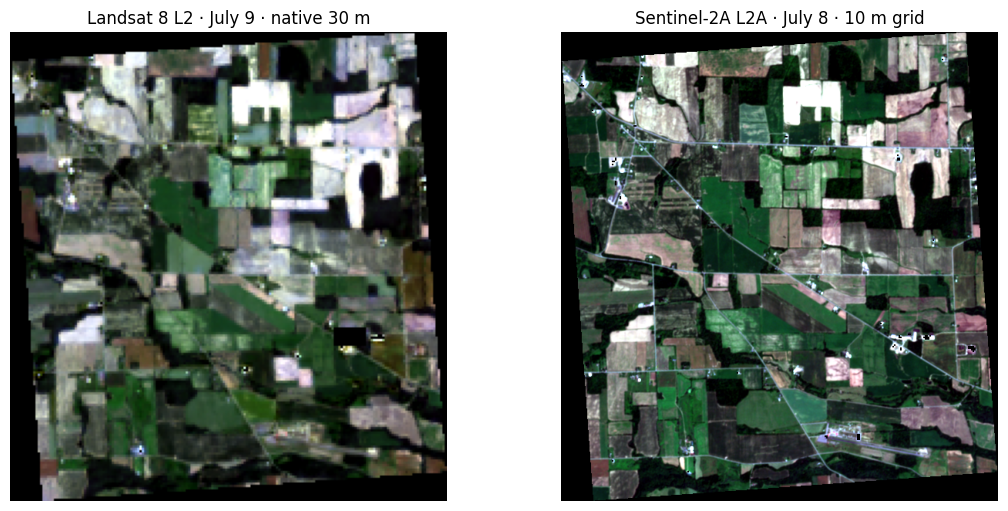

In [5]:
def rgb_stretch(cube, valid, bands=(2, 1, 0), percentiles=(2, 98)):  # contrast-stretched RGB image of a cube
    """Return a contrast-stretched RGB view from a (band, y, x) cube."""
    rgb = cube[list(bands)].transpose(1, 2, 0).copy()  # bands red, green, blue -> (rows, cols, 3)
    rgb_valid = valid & np.isfinite(rgb).all(axis=-1)  # valid pixels
    for channel in range(3):  # each colour channel
        values = rgb[..., channel][rgb_valid]  # its valid values
        low, high = np.percentile(values, percentiles)  # percentile limits
        # stretch to [0, 1]
        rgb[..., channel] = np.clip((rgb[..., channel] - low) / max(high - low, 1e-6), 0, 1)
    rgb[~rgb_valid] = 0  # invalid pixels in black
    return rgb  # the RGB image

fig, axes = plt.subplots(1, 2, figsize=(11, 5), constrained_layout=True)  # two panels
axes[0].imshow(rgb_stretch(landsat_filled, landsat_valid))  # Landsat
axes[0].set_title("Landsat 8 L2 · July 9 · native 30 m")  # title
axes[1].imshow(rgb_stretch(sentinel_filled, sentinel_valid))  # Sentinel-2
axes[1].set_title("Sentinel-2A L2A · July 8 · 10 m grid")  # title
for ax in axes:  # for both panels
    ax.set_axis_off()  # no axes
plt.show()  # draw

## Classical methods

### Run GeoLattice interpolation, sharpening, and reconstruction

`sr.upsample` provides bicubic and Lanczos baselines and returns georeferenced xarray data when given a `DataArray`. `sr.unsharp_mask` adds a fraction of high-frequency detail to bicubic output; this can oversharpen edges or noise. `sr.iterative_back_projection` starts from the coarse observation and iteratively reduces residuals under a simple Gaussian-blur/block-average model. None of these methods uniquely recovers spatial information the satellite did not measure; they are comparison baselines.


In [6]:
# Georeferenced xarray outputs retain the 10 m grid, CRS, and band coordinates.
bicubic_da = sr.upsample(landsat_filled_da, SCALE, method="bicubic")
lanczos_da = sr.upsample(landsat_filled_da, SCALE, method="lanczos")  # Lanczos interpolation to 10 m

# The sharpening/reconstruction methods work on NumPy band-first cubes.
unsharp = sr.unsharp_mask(bicubic_da.values, amount=0.6, sigma=1.0)
# iterative back-projection: refine bicubic until it reproduces the 30 m image
back_projection = sr.iterative_back_projection(
    landsat_filled, scale=SCALE, iterations=12, blur_sigma=1.0, step=0.5
)

classical = {  # the four classical estimates by name
    "Bicubic": bicubic_da.values,
    "Lanczos": lanczos_da.values,
    "Unsharp bicubic": unsharp,
    "Iterative back-projection": back_projection,
}
# all have the Sentinel-2 shape
assert all(array.shape == sentinel_values.shape for array in classical.values())
print({name: array.shape for name, array in classical.items()})  # their shapes

{'Bicubic': (6, 609, 567), 'Lanczos': (6, 609, 567), 'Unsharp bicubic': (6, 609, 567), 'Iterative back-projection': (6, 609, 567)}


## Deep learning: paired multispectral EDSR-style CNN

### Create a spatially separated patch dataset

The CNN needs examples of coarse/fine image pairs. Each 12×12 Landsat patch is paired with the corresponding 36×36 Sentinel patch. Patches are included only when at least 98% of their Landsat and shared Sentinel pixels are valid. A deterministic block-based split assigns neighboring patches together to either training or validation, reducing leakage from adjacent pixels. The held-out group is used only for scoring, never for gradient updates.


In [7]:
patch_records = []  # every usable patch: position, Landsat patch, Sentinel-2 patch, validation flag
height, width = landsat_valid.shape  # Landsat image size
for row in range(0, height - PATCH + 1, PATCH):  # patch rows
    for col in range(0, width - PATCH + 1, PATCH):  # patch columns
        low_mask = landsat_valid[row:row + PATCH, col:col + PATCH]  # Landsat validity of the patch
        fine_row, fine_col = row * SCALE, col * SCALE  # matching position on the 10 m grid
        fine_mask = valid_pair[fine_row:fine_row + PATCH * SCALE,  # validity of the matching 10 m patch
                               fine_col:fine_col + PATCH * SCALE]
        # keep patches that are at least 98 % valid in both
        if low_mask.mean() >= 0.98 and fine_mask.mean() >= 0.98:
            low_patch = landsat_filled[:, row:row + PATCH, col:col + PATCH]  # the 30 m input patch
            high_patch = sentinel_filled[:, fine_row:fine_row + PATCH * SCALE,  # the 10 m target patch
                                         fine_col:fine_col + PATCH * SCALE]
            # Keep each 2-by-2 group of adjacent patches in one split.
            tile_row, tile_col = row // PATCH, col // PATCH
            # every fourth 2 x 2 block of patches is held out for validation
            validation = ((tile_row // 2 + tile_col // 2) % 4) == 0
            patch_records.append((row, col, low_patch.copy(), high_patch.copy(), validation))  # store the patch

train_records = [record for record in patch_records if not record[4]]  # training patches
validation_records = [record for record in patch_records if record[4]]  # validation patches
if len(train_records) < 8 or len(validation_records) < 2:  # too few of either
    raise RuntimeError(f"Too few clear patches: {len(train_records)} train, "  # stop with a clear message
                       f"{len(validation_records)} validation")

# training inputs as a tensor
X_train = torch.from_numpy(np.stack([record[2] for record in train_records])).float()
Y_train = torch.from_numpy(np.stack([record[3] for record in train_records])).float()  # training targets
# validation inputs
X_validation = torch.from_numpy(np.stack([record[2] for record in validation_records])).float()
# validation targets
Y_validation = torch.from_numpy(np.stack([record[3] for record in validation_records])).float()
# shuffled batches of 8 patches
train_loader = DataLoader(TensorDataset(X_train, Y_train), batch_size=8, shuffle=True)
print(f"Patches: {len(patch_records)} total; {len(train_records)} training; "  # patch counts
      f"{len(validation_records)} held out")
print("Training pair shapes:", tuple(X_train.shape), tuple(Y_train.shape))  # input and target shapes

Patches: 194 total; 145 training; 49 held out
Training pair shapes: (145, 6, 12, 12) (145, 6, 36, 36)


### Build and train the network using GeoLattice

`build_sr_model` constructs the GeoLattice EDSR-style multispectral model with six inputs/outputs and a ×3 scale. `train_super_resolution` trains on paired tensors. Its loss combines reflectance L1 error, a spectral-angle penalty, and consistency between the predicted fine image and the observed coarse image after area downsampling. These terms encourage fidelity but do not remove the ambiguity in the unobserved high-frequency details. The training curve is a diagnostic; held-out spatial patches provide the comparison below.


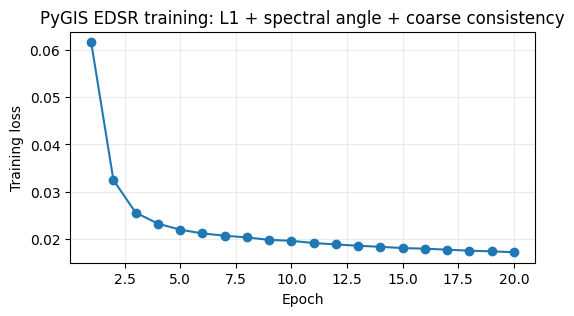

In [8]:
model = sr.build_sr_model(  # an EDSR network with 24 features and 3 residual blocks, upscaling by 3
    in_channels=len(BANDS), scale=SCALE, features=24, blocks=3, architecture="edsr"
)
# train it for 20 epochs (L1 loss plus spectral-angle and consistency terms)
history = sr.train_super_resolution(
    model, train_loader, epochs=20, lr=1e-4, device=DEVICE,
    sam_weight=0.05, consistency_weight=0.05,
)

fig, ax = plt.subplots(figsize=(6, 3))  # one panel
# training loss per epoch
ax.plot(np.arange(1, len(history["train_loss"]) + 1), history["train_loss"], marker="o")
ax.set(xlabel="Epoch", ylabel="Training loss",  # labels and title
       title="GeoLattice EDSR training: L1 + spectral angle + coarse consistency")
ax.grid(alpha=0.25)  # grid
plt.show()  # draw

## Inference and held-out evaluation

### Predict with tiled GeoLattice inference and calculate metrics

`predict_super_resolution` processes the full image in overlapping tiles and blends predictions to reduce tile seams. Passing the filled xarray Landsat image lets GeoLattice preserve its CRS and fine-grid coordinates. Held-out RMSE and PSNR summarize pixelwise error; SAM summarizes spectral-direction error across the six bands. These scores compare model outputs with a separate-date sensor reference, not with a known fine-resolution Landsat truth, so they are not absolute accuracy estimates.


In [9]:
neural_da = sr.predict_super_resolution(  # apply the trained network to the whole Landsat image
    model, landsat_filled_da, tile=64, overlap=12, batch_size=4, device=DEVICE
)
neural = np.asarray(neural_da.values, dtype="float32")  # the prediction as an array
assert neural.shape == sentinel_values.shape  # same shape as Sentinel-2

candidates = {**classical, "CNN (paired patches)": neural}  # classical estimates plus the network

def heldout_metrics(prediction):  # scores on the held-out patches only
    """Compute RMSE, unit-range PSNR, and SAM over valid held-out pixels."""
    prediction_parts, reference_parts = [], []  # pieces of prediction and reference
    for row, col, _, _, _ in validation_records:  # every validation patch
        r0, c0 = row * SCALE, col * SCALE  # its position on the 10 m grid
        mask = valid_pair[r0:r0 + PATCH * SCALE, c0:c0 + PATCH * SCALE]  # valid pixels of the patch
        if mask.any():  # skip patches without valid pixels
            # the predicted patch, valid pixels only
            prediction_parts.append(prediction[:, r0:r0 + PATCH * SCALE,
                                               c0:c0 + PATCH * SCALE][:, mask])
            # the reference patch, valid pixels only
            reference_parts.append(sentinel_values[:, r0:r0 + PATCH * SCALE,
                                                   c0:c0 + PATCH * SCALE][:, mask])
    estimate = np.concatenate(prediction_parts, axis=1)  # all prediction pixels
    reference = np.concatenate(reference_parts, axis=1)  # all reference pixels
    rmse = float(np.sqrt(np.mean((estimate - reference) ** 2)))  # root-mean-square error
    dot = np.sum(estimate * reference, axis=0)  # dot product of the spectra
    norms = np.linalg.norm(estimate, axis=0) * np.linalg.norm(reference, axis=0)  # product of their lengths
    sam = np.degrees(np.arccos(np.clip(dot / np.maximum(norms, 1e-8), -1, 1)))  # spectral angle of every pixel
    psnr = float(20 * np.log10(1 / max(rmse, 1e-12)))  # PSNR for reflectance in [0, 1]
    return {"RMSE": rmse, "PSNR (range=1)": psnr, "SAM (degrees)": float(sam.mean())}  # the three scores

scores = {name: heldout_metrics(prediction) for name, prediction in candidates.items()}  # score every method
score_table = xr.Dataset({  # scores as a table (method x metric)
    metric: xr.DataArray([scores[name][metric] for name in scores], dims="method",
                         coords={"method": list(scores)})
    for metric in next(iter(scores.values()))
}).to_dataframe()
display(score_table.sort_values("RMSE").style.format("{:.4f}"))  # best method first

,RMSE,PSNR (range=1),SAM (degrees)
method,,,
CNN (paired patches),0.0177,35.0449,2.3818
Lanczos,0.0240,32.3978,3.8036
Iterative back-projection,0.0242,32.3352,3.8099
Unsharp bicubic,0.0243,32.3002,3.8722
Bicubic,0.0244,32.2583,3.9101


### Visualize the held-out comparison

The six panels show the Sentinel-2 reference and each Landsat-based estimate using the same display stretch. The validity mask is applied to every panel so masked cloud and outside-AOI pixels are not mistaken for model output. The reference is still Sentinel-2; visual similarity cannot distinguish spatial detail from temporal or sensor-response differences.


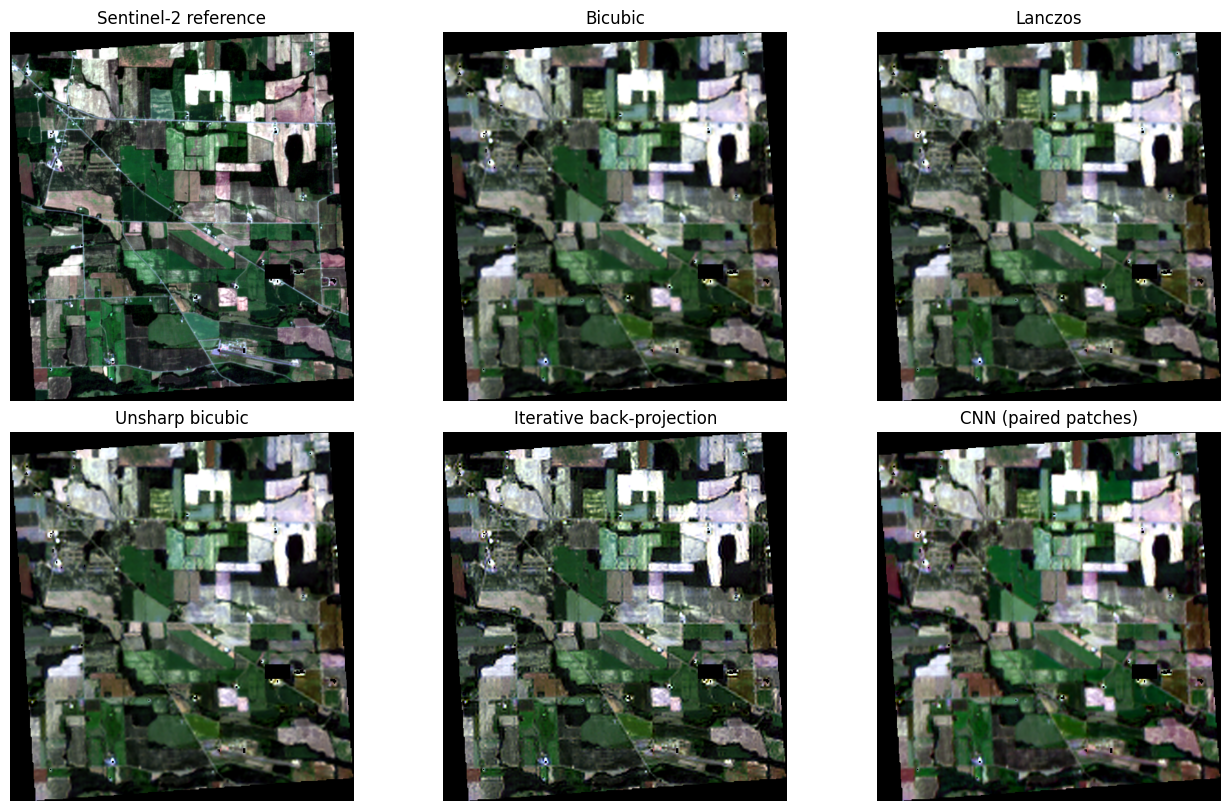

In [10]:
image_sets = {"Sentinel-2 reference": sentinel_filled, **candidates}  # the reference plus every estimate
plot_order = ["Sentinel-2 reference", "Bicubic", "Lanczos", "Unsharp bicubic",  # panel order
              "Iterative back-projection", "CNN (paired patches)"]
fig, axes = plt.subplots(2, 3, figsize=(13, 8), constrained_layout=True)  # 2 x 3 panels
for ax, name in zip(axes.flat, plot_order):  # one panel per image
    ax.imshow(rgb_stretch(image_sets[name], valid_pair))  # RGB view, valid pixels only
    ax.set_title(name)  # title
    ax.set_axis_off()  # no axes
plt.show()  # draw

## Export georeferenced products with GeoLattice

### Mask outputs and write Cloud-Optimized GeoTIFFs

The final products keep the Landsat clear/AOI footprint: invalid locations become NaN/nodata rather than retaining the temporary nearest-neighbor fills. Each candidate is a six-band xarray image on the 10 m target grid. `rs.write` is GeoLattice's raster writer and creates a Cloud-Optimized GeoTIFF by default. Output metadata records method and warns that 10 m is the output grid, not native Landsat detail.


In [11]:
# Use the bicubic xarray output as a template for CRS, transform, coordinates, and band names.
template_10m = bicubic_da
output_valid = valid_pair  # clear and finite in both scenes, inside the shared AOI

def as_valid_georeferenced(cube, method_name):  # wrap an estimate as a georeferenced DataArray
    """Wrap an array as the common-grid DataArray and restore invalid pixels as nodata."""
    values = np.where(output_valid[None, :, :], cube, np.nan).astype("float32")  # invalid pixels -> NaN
    # the 10 m template with these values and NaN as no-data
    result = template_10m.copy(data=values).rio.write_nodata(np.nan)
    result.attrs = {  # record what the file contains
        "method": method_name,
        "source_scene": landsat_metadata["scene_id"],
        "reference_scene": sentinel_metadata["scene_id"],
        "interpretation": "10 m output grid; estimated detail is not native Landsat measurement",
    }
    return result  # the DataArray

for name, cube in candidates.items():  # every estimate
    safe_name = name.lower().replace(" ", "_").replace("(", "").replace(")", "")  # a file-safe name
    path = OUTPUT_DIR / f"{safe_name}.tif"  # output path
    rs.write(as_valid_georeferenced(cube, name), path, cog=True)  # save as a Cloud-Optimised GeoTIFF
    print("Wrote", path)  # report the file

Wrote /media/zia207/SSD/GitHub/GeoLattice/Tutorials/notebooks/09_remote_sensing/09_08_image_super_resolution/data/super_resolution_outputs/bicubic.tif
Wrote /media/zia207/SSD/GitHub/GeoLattice/Tutorials/notebooks/09_remote_sensing/09_08_image_super_resolution/data/super_resolution_outputs/lanczos.tif
Wrote /media/zia207/SSD/GitHub/GeoLattice/Tutorials/notebooks/09_remote_sensing/09_08_image_super_resolution/data/super_resolution_outputs/unsharp_bicubic.tif
Wrote /media/zia207/SSD/GitHub/GeoLattice/Tutorials/notebooks/09_remote_sensing/09_08_image_super_resolution/data/super_resolution_outputs/iterative_back-projection.tif
Wrote /media/zia207/SSD/GitHub/GeoLattice/Tutorials/notebooks/09_remote_sensing/09_08_image_super_resolution/data/super_resolution_outputs/cnn_paired_patches.tif


## Interpretation

- **Bicubic and Lanczos** are essential resampling baselines, not detail-recovery methods.
- **Unsharp masking** adds local contrast; inspect it for ringing and noise amplification.
- **Iterative back-projection** enforces the chosen blur/downsampling assumption, but its fine-scale solution is not unique.
- **The EDSR-style CNN** learns a mapping from this Landsat/Sentinel pair. Its held-out scores measure agreement with Sentinel-2 only; they do not prove recovered Landsat detail.
- **SWIR1/SWIR2** originate at Sentinel-2's native 20 m resolution and were placed on the 10 m output grid by interpolation. A 10 m grid does not change their native information content.

The scenes are one day apart and both Level-2 reflectance, but residual co-registration, atmospheric correction, spectral response, and the Sentinel SWIR bands still differ. For operational use, validate on multiple near-coincident scenes, match the sensor point-spread functions and bandpasses, check coarse-observation consistency, and evaluate downstream decisions. Label any result as model-derived super-resolution, not as native 10 m Landsat.
